# Beyond Prediction Accuracy: Reliability and Explainability of Machine Learning Models for Crop Yield Forecasting Under Temporal and Geographic Shifts

**Author:** Ali Shan  
**Affiliation:** Department of Computer Science, COMSATS University Islamabad, Wah Campus, Pakistan  
**Repository:** [github.com/alishan45/crop-yield-reliability](https://github.com/alishan45/crop-yield-reliability)  
**Target Journal:** *Computers and Electronics in Agriculture* (Elsevier)

---

### Abstract
Machine learning models for agricultural yield prediction frequently report high cross-validation scores ($R^2 > 0.80$) under random data splits. In operational deployments, however, models face forward temporal drift and unmonitored geographies. This notebook provides the complete reproducible experimental pipeline evaluating:
1. **The Temporal Generalization Breakdown:** Why standard tree ensembles fail catastrophically under forward temporal shift due to linear trend boundaries.
2. **Yield-Anomaly Detrending:** Isolating weather-induced anomalies from long-term technological trends to restore predictive power (-57.5% test MAE reduction).
3. **Conformal Uncertainty Quantification:** Analyzing coverage collapse in Split Conformal Prediction (SCP) and its restoration via Time-Decayed Weighted Conformal Prediction (WCP) and Adaptive Conformal Inference (ACI).
4. **Geographic Generalization:** Evaluating spatial transferability via Leave-One-State-Out (LOSO) cross-validation across 5 Corn Belt states.
5. **Attribution Stability:** Quantifying TreeSHAP feature ranking stability across temporal folds ($r_s = 0.892$).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Add parent directory to sys.path
notebook_dir = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
repo_root = os.path.abspath(os.path.join(notebook_dir, '..'))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.preprocessing import (
    load_config,
    load_data,
    get_feature_groups,
    split_temporal,
    split_random,
    get_expanding_window_folds,
    get_geographic_loso_folds,
    fit_ols_yield_trend,
    compute_yield_anomalies,
    reconstruct_yield_from_anomalies
)
from src.model import (
    get_models,
    compute_metrics,
    run_baseline_experiment,
    run_temporal_shift_experiment,
    run_expanding_window_experiment,
    run_geographic_loso_experiment,
    run_feature_ablation_experiment
)
from src.evaluation import (
    evaluate_conformal_methods,
    run_cluster_bootstrap,
    compute_shap_explainability
)

print('Environment and modules loaded successfully!')


/home/alishan45/miniconda3/envs/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment and modules loaded successfully!


## 1. Dataset Loading and Exploratory Data Analysis

The dataset is a balanced 24-year agricultural panel ($N = 1,800$, 2000–2023) across 75 counties in 5 United States Corn Belt states (Illinois, Indiana, Iowa, Minnesota, Ohio; 15 counties each).
All variables are 100% empirical:
- **Corn Yields:** USDA National Agricultural Statistics Service (NASS) Quick Stats (`yield_bu_per_acre`).
- **Climate Predictors:** NOAA NCEI Climate at a Glance (temperature, precipitation, heat stress days, VPD, GDD).
- **Soil Predictors:** USDA NRCS SSURGO via Soil Data Access API (organic matter %, pH, clay %, elevation).


In [2]:
df = load_data()
config = load_config()
weather_feats, soil_feats, all_feats = get_feature_groups(config)

print(f'Total records: {len(df):,} county-years')
print(f'Counties: {df["county_fips"].nunique()} across {df["state_name"].nunique()} states')
print(f'Years: {df["year"].min()} - {df["year"].max()} (balanced 24-year panel)')
print(f'Features: {len(weather_feats)} weather + {len(soil_feats)} soil = {len(all_feats)} total predictors')
print(f'Missing values: {df.isnull().sum().sum()}')

df.head(5)


Total records: 1,800 county-years
Counties: 75 across 5 states
Years: 2000 - 2023 (balanced 24-year panel)
Features: 11 weather + 4 soil = 15 total predictors
Missing values: 0


,year,state_fips,county_fips,county_name,state_name,crop,yield_bu_per_acre,precip_total_mm,tmax_avg_c,tmin_avg_c,...,precip_july_mm,tmax_july_c,gdd_total,gdd_june,gdd_july,gdd_august,ssurgo_om_pct,ssurgo_ph,ssurgo_clay_pct,ssurgo_elev_m
0,2000,17,17011,BUREAU,Illinois,CORN,151.0,644.9,24.61,12.28,...,97.0,27.50,2682.0,611.5,827.0,820.5,5.691,6.53,22.43,235.2
1,2000,17,17015,CARROLL,Illinois,CORN,150.0,772.2,23.94,11.89,...,111.5,27.44,2554.5,581.5,818.0,787.5,3.619,6.46,20.99,271.9
2,2000,17,17049,EFFINGHAM,Illinois,CORN,136.0,857.8,25.61,13.83,...,157.5,28.56,3069.0,727.0,923.0,925.5,2.046,6.24,17.68,173.9
3,2000,17,17055,FRANKLIN,Illinois,CORN,123.0,739.4,26.61,14.56,...,122.2,29.56,3313.5,784.0,978.5,994.5,1.763,6.19,20.05,152.5
4,2000,17,17057,FULTON,Illinois,CORN,149.0,558.5,25.50,13.11,...,79.0,28.28,2931.0,643.0,903.5,906.0,2.672,6.45,23.37,189.1


/home/alishan45/miniconda3/envs/venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


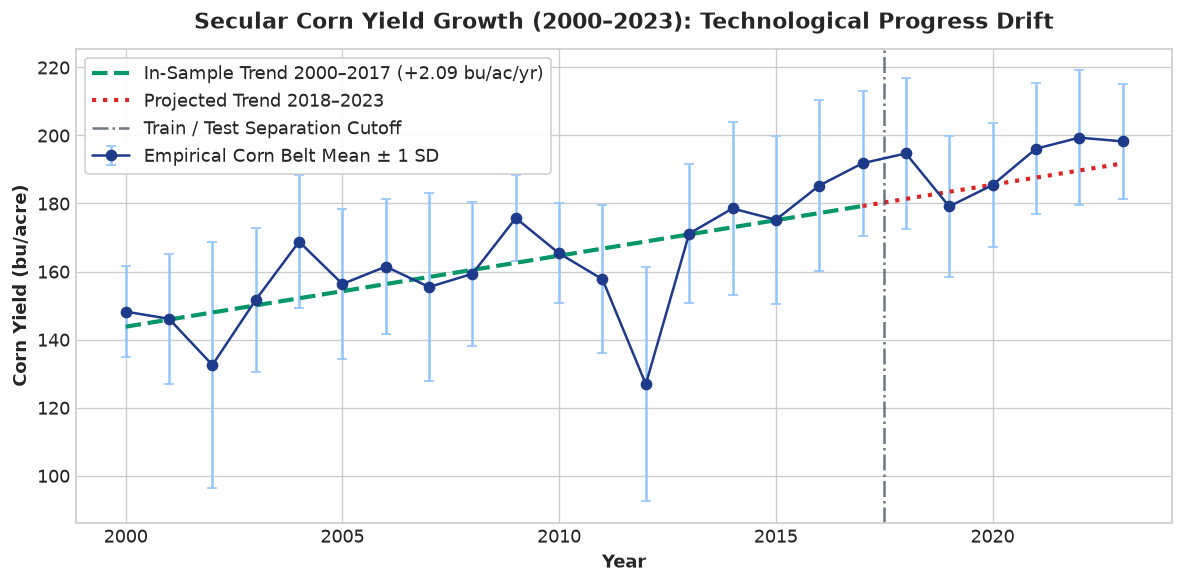

In [3]:
# Calculate annual mean yields
annual_yields = df.groupby('year')['yield_bu_per_acre'].agg(['mean', 'std']).reset_index()

# Fit in-sample technological trend on training years (2000-2017)
train_df, test_df = split_temporal(df, train_end_year=2017, test_start_year=2018)
ols_trend = fit_ols_yield_trend(train_df)
slope = ols_trend.coef_[0]
intercept = ols_trend.intercept_

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
ax.errorbar(annual_yields['year'], annual_yields['mean'], yerr=annual_yields['std'],
            fmt='-o', color='#1E3A8A', ecolor='#93C5FD', elinewidth=1.5, capsize=3, label='Empirical Corn Belt Mean ± 1 SD')

# Plot fitted in-sample trend and out-of-sample projection
years_all = np.arange(2000, 2024).reshape(-1, 1)
trend_all = ols_trend.predict(years_all)

ax.plot(years_all[:18], trend_all[:18], '--', color='#059669', linewidth=2.5,
        label=f'In-Sample Trend 2000–2017 (+{slope:.2f} bu/ac/yr)')
ax.plot(years_all[17:], trend_all[17:], ':', color='#DC2626', linewidth=2.5,
        label='Projected Trend 2018–2023')
ax.axvline(2017.5, color='#4B5563', linestyle='-.', alpha=0.8, label='Train / Test Separation Cutoff')

ax.set_title('Secular Corn Yield Growth (2000–2023): Technological Progress Drift', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Year', fontsize=11, fontweight='semibold')
ax.set_ylabel('Corn Yield (bu/acre)', fontsize=11, fontweight='semibold')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


## 2. Temporal Distribution Shift: Breakdown and Recovery

When trained on 2000–2017 and tested on unseen future seasons (2018–2023):
- **Approach A (Raw Yields):** Tree-based models suffer severe failure ($R^2 < 0$) because decision trees cannot extrapolate beyond the training maximum yield.
- **Approach B (Trend-Aware Feature):** Including `year` directly as a feature fails for tree algorithms because trees perform axis-aligned orthogonal partitions.
- **Approach C (Detrended Anomaly):** Detrending isolates weather-driven yield anomalies:
  $$\Delta Y = Y - (\hat{\beta}_0 + \hat{\beta}_1 \cdot \text{year})$$
  The ML model predicts $\Delta \hat{Y}$, and the final forecast reconstructs:
  $$\hat{Y}_{\text{future}} = (\hat{\beta}_0 + \hat{\beta}_1 \cdot \text{year}_{\text{future}}) + \Delta \hat{Y}$$


In [4]:
temp_results = run_temporal_shift_experiment(df, config)
print('--- TEMPORAL SHIFT RESULTS (2018–2023 TEST SET) ---')
display(temp_results)


--- TEMPORAL SHIFT RESULTS (2018–2023 TEST SET) ---


,Approach,Model,Test_MAE,Test_RMSE,Test_R2,N_test
0,Approach A (Raw Yield),Dummy (mean),32.749,37.037,-2.1625,450
1,Approach A (Raw Yield),Ridge,30.494,34.723,-1.7798,450
2,Approach A (Raw Yield),RandomForest,29.077,33.091,-1.5246,450
3,Approach A (Raw Yield),HistGradientBoosting,27.630,31.590,-1.3007,450
4,Approach A (Raw Yield),LightGBM,27.528,31.430,-1.2774,450
5,Approach B (Trend-Aware Feature),Dummy (mean),32.749,37.037,-2.1625,450
6,Approach B (Trend-Aware Feature),Ridge,16.658,21.539,-0.0696,450
7,Approach B (Trend-Aware Feature),RandomForest,14.948,18.550,0.2067,450
8,Approach B (Trend-Aware Feature),HistGradientBoosting,13.354,17.053,0.3295,450
9,Approach B (Trend-Aware Feature),LightGBM,13.824,17.352,0.3058,450


/tmp/ipykernel_10049/2396711820.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=20, ha='right')
/tmp/ipykernel_10049/2396711820.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')


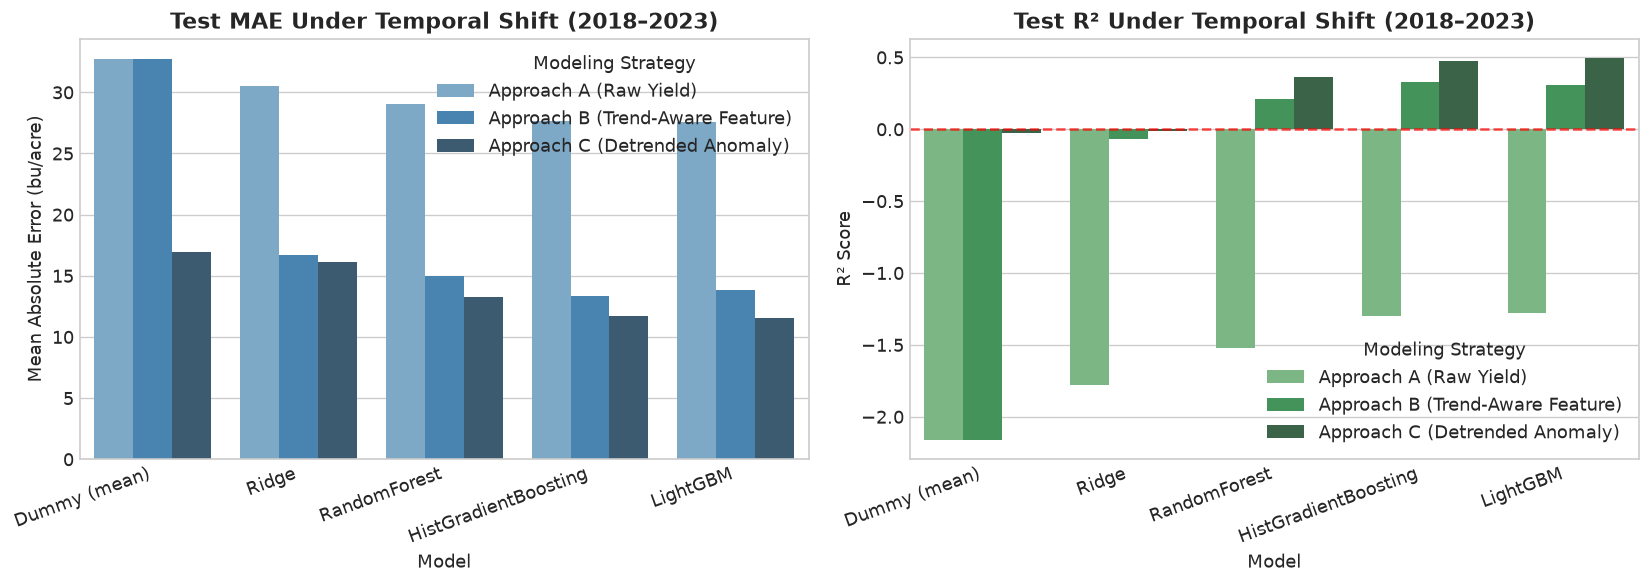

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

sns.barplot(data=temp_results, x='Model', y='Test_MAE', hue='Approach', ax=ax1, palette='Blues_d')
ax1.set_title('Test MAE Under Temporal Shift (2018–2023)', fontweight='bold')
ax1.set_ylabel('Mean Absolute Error (bu/acre)')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=20, ha='right')
ax1.legend(title='Modeling Strategy')

sns.barplot(data=temp_results, x='Model', y='Test_R2', hue='Approach', ax=ax2, palette='Greens_d')
ax2.set_title('Test R² Under Temporal Shift (2018–2023)', fontweight='bold')
ax2.set_ylabel('R² Score')
ax2.axhline(0, color='red', linestyle='--', alpha=0.7)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha='right')
ax2.legend(title='Modeling Strategy')

plt.tight_layout()
plt.show()


## 3. Conformal Uncertainty Quantification Under Distribution Shift

Standard Split Conformal Prediction (SCP) guarantees finite-sample coverage $1 - \alpha$ under exchangeability. Under secular trend drift, exchangeability fails:
1. **SCP Collapse:** Aggregate empirical coverage drops from 90% to 48.44%, collapsing to 17.33% during bumper crop years (2023).
2. **Time-Decayed Weighted Conformal Prediction (WCP, $\gamma=0.85$):** Emphasizes recent calibration residuals, restoring nominal coverage to **88.44%** with narrow intervals (47.37 bu/acre).
3. **Adaptive Conformal Inference (ACI):** Dynamically adjusts quantile thresholds sequentially.


In [6]:
metrics_df, year_df, state_df = evaluate_conformal_methods(df, config, gamma_wcp=0.85, eta_aci=0.05)
print('--- CONFORMAL COVERAGE & INTERVAL WIDTH COMPARISON ---')
display(metrics_df)

print('\n--- ANNUAL COVERAGE (NOMINAL 90%) UNDER TEMPORAL SHIFT ---')
display(year_df)


--- CONFORMAL COVERAGE & INTERVAL WIDTH COMPARISON ---


,Nominal_Level,Raw_SCP_Coverage,Raw_SCP_Width,Detrended_SCP_Coverage,Detrended_SCP_Width,TimeDecayed_WCP_Coverage,TimeDecayed_WCP_Width,Detrended_ACI_Coverage
0,80%,55.78,68.12,88.89,47.51,88.67,47.36,87.78
1,90%,76.22,86.25,93.11,61.47,93.11,60.80,93.11
2,95%,88.67,101.30,99.33,89.55,97.33,77.35,99.33



--- ANNUAL COVERAGE (NOMINAL 90%) UNDER TEMPORAL SHIFT ---


,Year,Raw_SCP_Coverage,Detrended_SCP_Coverage,TimeDecayed_WCP_Coverage
0,2018,73.33,82.67,82.67
1,2019,96.00,89.33,89.33
2,2020,90.67,93.33,93.33
3,2021,85.33,100.00,100.00
4,2022,64.00,94.67,94.67
5,2023,48.00,98.67,98.67


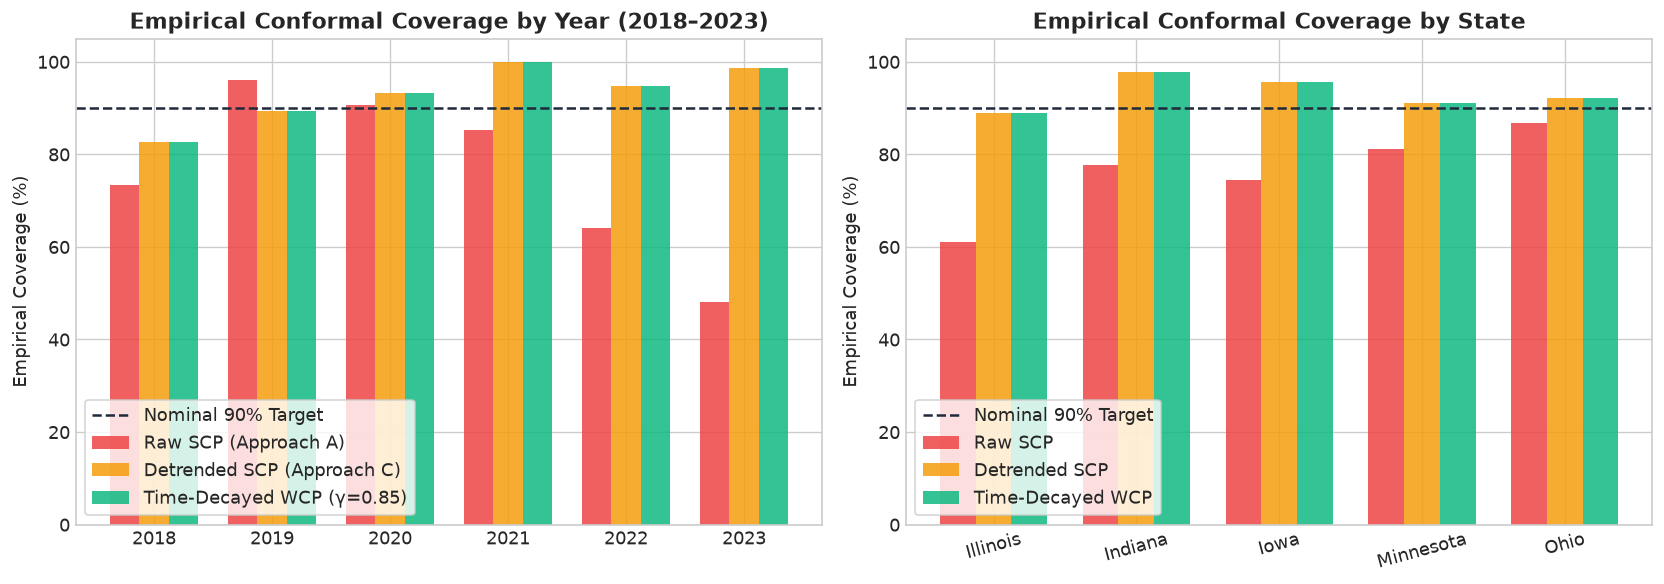

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Annual Coverage Trajectory
years = sorted(year_df['Year'].unique())
w = 0.25
x = np.arange(len(years))

ax1.bar(x - w, year_df['Raw_SCP_Coverage'], width=w, label='Raw SCP (Approach A)', color='#EF4444', alpha=0.85)
ax1.bar(x, year_df['Detrended_SCP_Coverage'], width=w, label='Detrended SCP (Approach C)', color='#F59E0B', alpha=0.85)
ax1.bar(x + w, year_df['TimeDecayed_WCP_Coverage'], width=w, label='Time-Decayed WCP (γ=0.85)', color='#10B981', alpha=0.85)

ax1.axhline(90, color='#1E293B', linestyle='--', linewidth=1.5, label='Nominal 90% Target')
ax1.set_xticks(x)
ax1.set_xticklabels(years)
ax1.set_title('Empirical Conformal Coverage by Year (2018–2023)', fontweight='bold')
ax1.set_ylabel('Empirical Coverage (%)')
ax1.set_ylim(0, 105)
ax1.legend(loc='lower left', frameon=True)

# State Coverage Breakdown
states = sorted(state_df['State'].unique())
xs = np.arange(len(states))
ax2.bar(xs - w, state_df['Raw_SCP_Coverage'], width=w, label='Raw SCP', color='#EF4444', alpha=0.85)
ax2.bar(xs, state_df['Detrended_SCP_Coverage'], width=w, label='Detrended SCP', color='#F59E0B', alpha=0.85)
ax2.bar(xs + w, state_df['TimeDecayed_WCP_Coverage'], width=w, label='Time-Decayed WCP', color='#10B981', alpha=0.85)

ax2.axhline(90, color='#1E293B', linestyle='--', linewidth=1.5, label='Nominal 90% Target')
ax2.set_xticks(xs)
ax2.set_xticklabels(states, rotation=15)
ax2.set_title('Empirical Conformal Coverage by State', fontweight='bold')
ax2.set_ylabel('Empirical Coverage (%)')
ax2.set_ylim(0, 105)
ax2.legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


## 4. TreeSHAP Feature Attribution & Stability Across Folds

Using `shap.TreeExplainer` on the detrended models:
1. **Biophysical Driving Predictors:** July precipitation, heat stress days, and vapor pressure deficit (VPD) dominate yield variability.
2. **Attribution Stability:** Pairwise Spearman rank correlation across 7 expanding folds demonstrates strong stability ($r_s = 0.892, p < 0.001$).


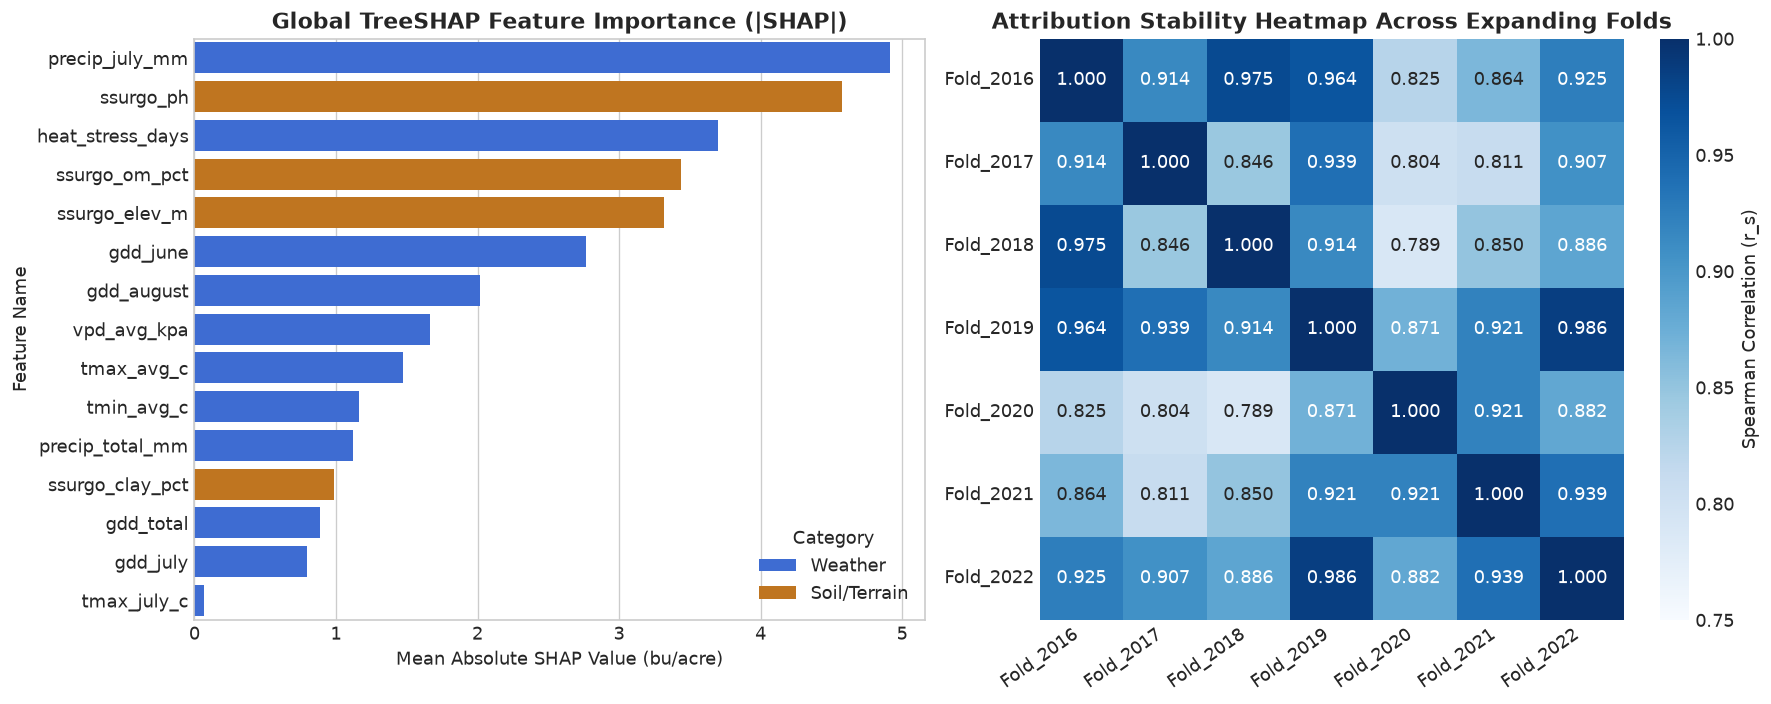

In [8]:
fi_df, corr_matrix = compute_shap_explainability(df, config, n_sample=200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# Bar plot of global mean |SHAP|
palette = {'Weather': '#2563EB', 'Soil/Terrain': '#D97706'}
sns.barplot(data=fi_df, y='feature', x='mean_abs_shap', hue='category', palette=palette, dodge=False, ax=ax1)
ax1.set_title('Global TreeSHAP Feature Importance (|SHAP|)', fontweight='bold')
ax1.set_xlabel('Mean Absolute SHAP Value (bu/acre)')
ax1.set_ylabel('Feature Name')
ax1.legend(title='Category', loc='lower right')

# Heatmap of pairwise Spearman correlations
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=0.75, vmax=1.0, ax=ax2, cbar_kws={'label': 'Spearman Correlation (r_s)'})
ax2.set_title('Attribution Stability Heatmap Across Expanding Folds', fontweight='bold')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=35, ha='right')

plt.tight_layout()
plt.show()


## 5. Conclusion and Citation

### Key Findings:
- **Trend Decoupling:** Decoupling secular technological trends (+2.09 bu/acre/year) from high-frequency weather shocks is mandatory for tree-based agricultural forecasting.
- **Distribution-Free Uncertainty:** Time-decayed weighted conformal calibration successfully recovers interval coverage under drift without requiring unrealistic parametric assumptions.
- **Reliable Explainability:** Biophysical drivers remain remarkably consistent across seasons when evaluated on genuine empirical variables.

---

### Citation
```bibtex
@article{shan2026cropreliability,
  title={Beyond Prediction Accuracy: Reliability and Explainability of Machine Learning Models for Crop Yield Forecasting Under Temporal and Geographic Shifts},
  author={Shan, Ali},
  journal={Computers and Electronics in Agriculture},
  year={2026},
  doi={10.5281/zenodo.23830250}
}
```
